In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler



In [2]:
df = pd.read_csv('used_car_prediction.csv')

In [3]:
df.tail()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,price_usd,brand,transmission,color,service_history,accidents_reported,insurance_valid
9995,1996,15.25,1500,Petrol,2,5498.71,Hyundai,Manual,Silver,NaN,0,Yes
9996,1997,14.45,5000,Diesel,1,9588.31,Honda,Manual,Gray,Full,0,Yes
9997,2002,19.41,1000,Diesel,4,4557.10,Kia,Manual,Black,Full,0,Yes
9998,2005,12.95,4000,Petrol,5,7413.59,BMW,Automatic,Blue,Full,0,Yes
9999,2007,18.81,5000,Petrol,1,11634.09,BMW,Automatic,Silver,Full,0,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           10000 non-null  int64  
 1   mileage_kmpl        10000 non-null  float64
 2   engine_cc           10000 non-null  int64  
 3   fuel_type           10000 non-null  str    
 4   owner_count         10000 non-null  int64  
 5   price_usd           10000 non-null  float64
 6   brand               10000 non-null  str    
 7   transmission        10000 non-null  str    
 8   color               10000 non-null  str    
 9   service_history     7962 non-null   str    
 10  accidents_reported  10000 non-null  int64  
 11  insurance_valid     10000 non-null  str    
dtypes: float64(2), int64(4), str(6)
memory usage: 937.6 KB


In [5]:
df.shape

(10000, 12)

In [6]:
df.describe()

,make_year,mileage_kmpl,engine_cc,owner_count,price_usd,accidents_reported
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2009.206900,17.960753,2287.130000,3.003500,7179.754532,0.492200
std,8.373858,5.025486,1291.276927,1.418904,2795.270940,0.694109
min,1995.000000,5.000000,800.000000,1.000000,1000.000000,0.000000
25%,2002.000000,14.540000,1200.000000,2.000000,5176.547500,0.000000
50%,2009.000000,17.970000,1800.000000,3.000000,6961.260000,0.000000
75%,2016.000000,21.352500,3000.000000,4.000000,8993.732500,1.000000
max,2023.000000,35.000000,5000.000000,5.000000,17647.630000,5.000000


In [7]:
df.isnull().sum()

make_year                0
mileage_kmpl             0
engine_cc                0
fuel_type                0
owner_count              0
price_usd                0
brand                    0
transmission             0
color                    0
service_history       2038
accidents_reported       0
insurance_valid          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

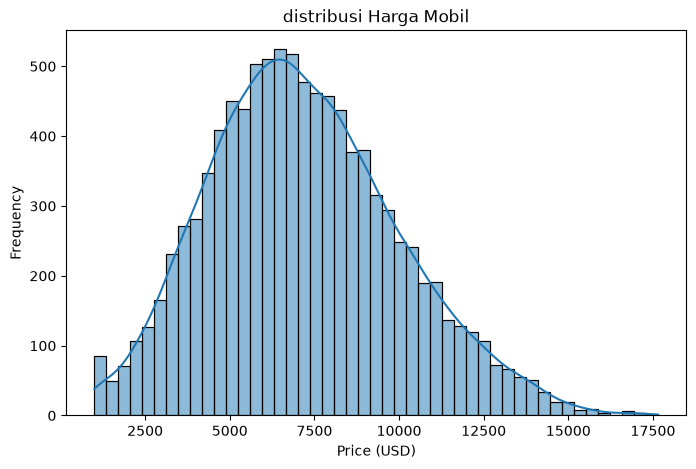

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='price_usd', kde=True)

plt.title('distribusi Harga Mobil')
plt.xlabel('Price (USD)')
plt.ylabel('Frequency')
plt.show()

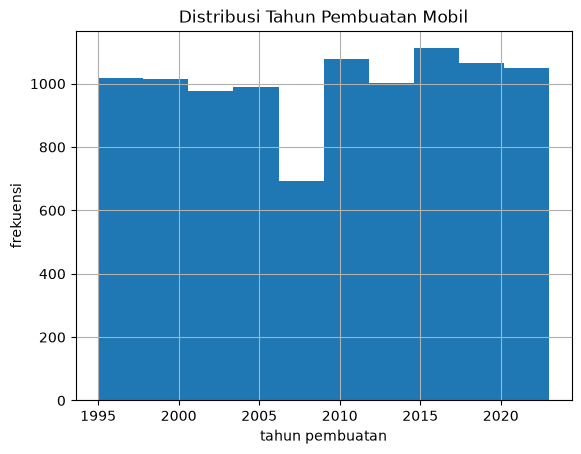

In [10]:
df['make_year'].hist()
plt.title('Distribusi Tahun Pembuatan Mobil')
plt.xlabel('tahun pembuatan')
plt.ylabel('frekuensi')

plt.show()

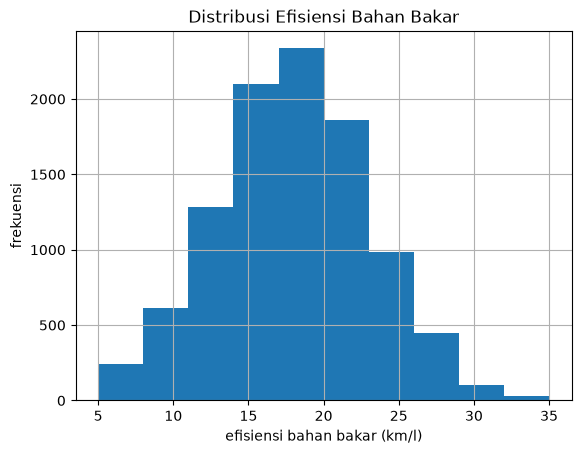

In [11]:
df['mileage_kmpl'].hist()
plt.title('Distribusi Efisiensi Bahan Bakar')
plt.xlabel('efisiensi bahan bakar (km/l)')
plt.ylabel('frekuensi')
plt.show()

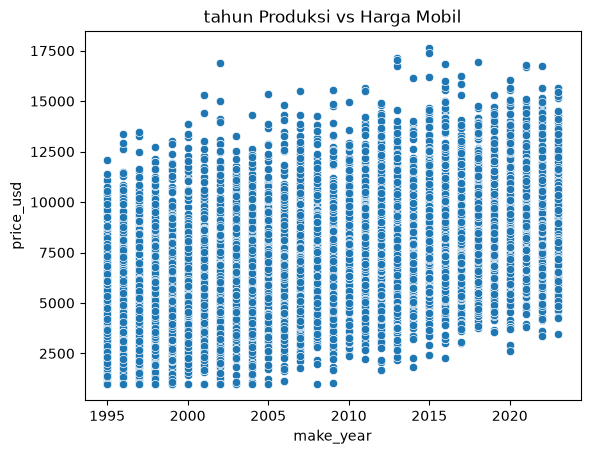

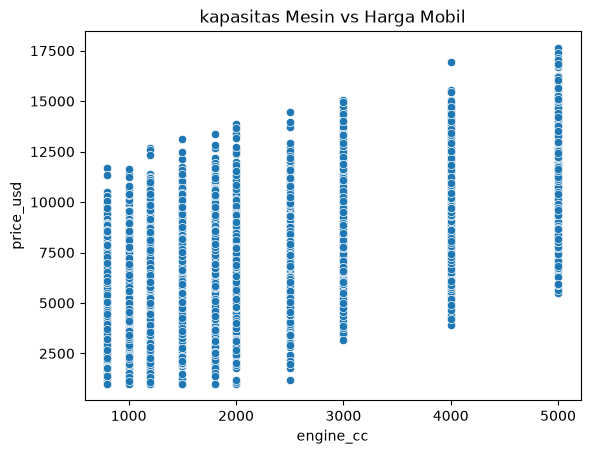

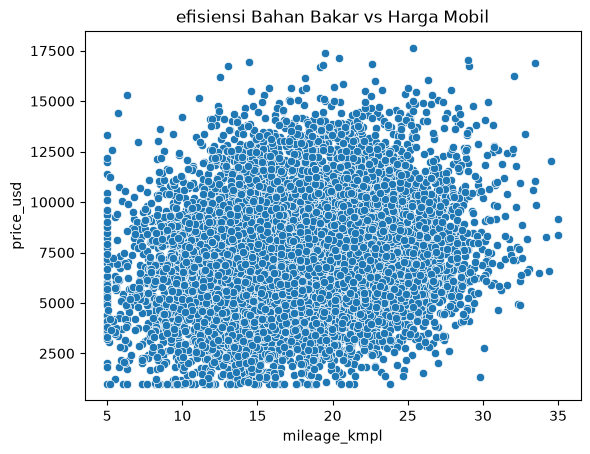

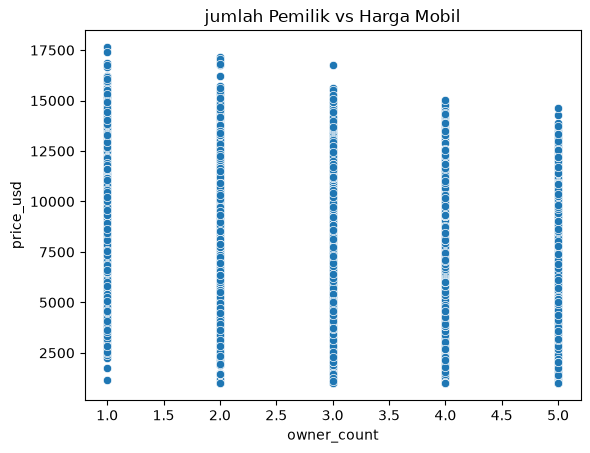

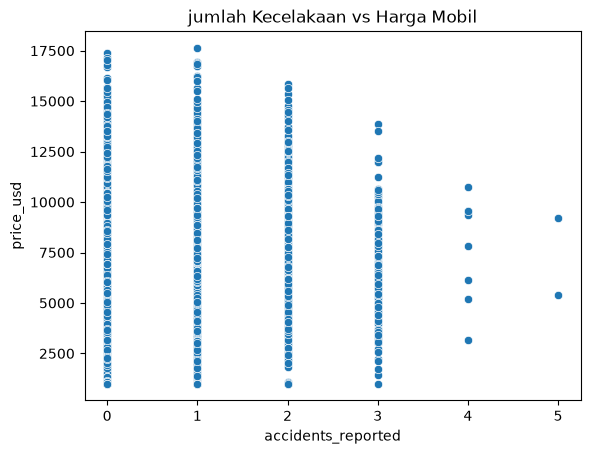

In [12]:
# 1. tahun produksi vs harga
sns.scatterplot(data=df, x='make_year', y='price_usd')
plt.title('tahun Produksi vs Harga Mobil')
plt.show()

# 2. kapasitas mesin vs harga
sns.scatterplot(data=df, x='engine_cc', y='price_usd')
plt.title('kapasitas Mesin vs Harga Mobil')
plt.show()

# 3. efisiensi bahan bakar vs harga
sns.scatterplot(data=df, x='mileage_kmpl', y='price_usd')
plt.title('efisiensi Bahan Bakar vs Harga Mobil')
plt.show()

# 4. jumlah pemilik sebelumnya vs harga
sns.scatterplot(data=df, x='owner_count', y='price_usd')
plt.title('jumlah Pemilik vs Harga Mobil')
plt.show()

# 9. jumlah kecelakaan vs harga
sns.scatterplot(data=df, x='accidents_reported', y='price_usd')
plt.title('jumlah Kecelakaan vs Harga Mobil')
plt.show()

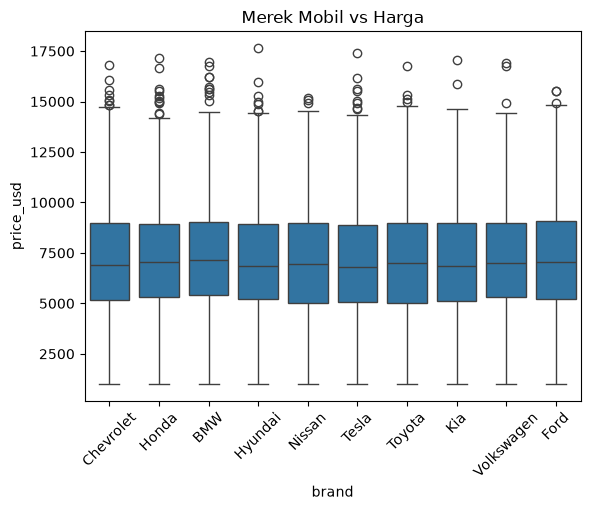

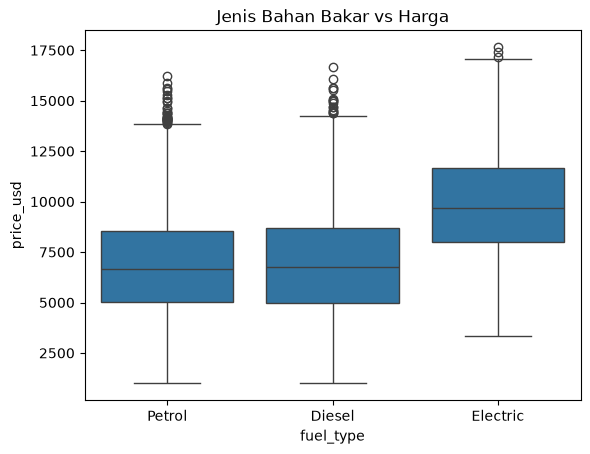

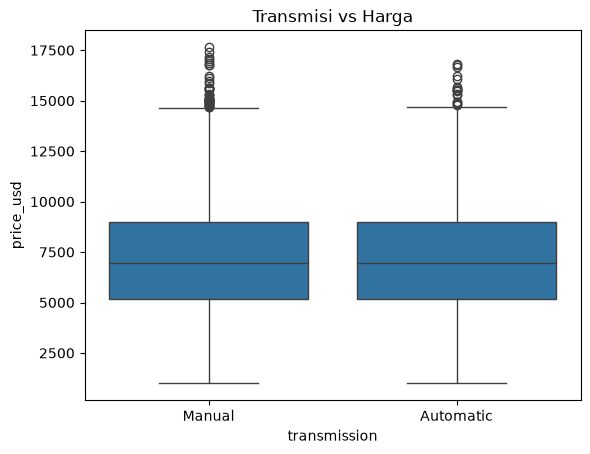

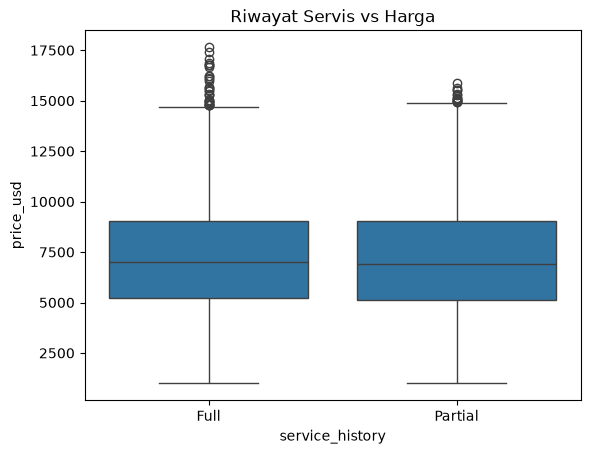

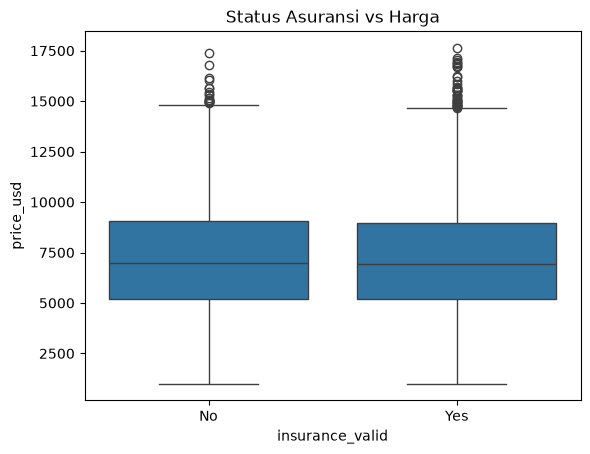

In [13]:
# 5. merek mobil vs harga
sns.boxplot(data=df, x='brand', y='price_usd')
plt.title('Merek Mobil vs Harga')
plt.xticks(rotation=45)
plt.show()

# 6. jenis bahan bakar vs harga
sns.boxplot(data=df, x='fuel_type', y='price_usd')
plt.title('Jenis Bahan Bakar vs Harga')
plt.show()

# 7. jenis transmisi vs harga
sns.boxplot(data=df, x='transmission', y='price_usd')
plt.title('Transmisi vs Harga')
plt.show()

# 8. riwayat servis vs harga
sns.boxplot(data=df, x='service_history', y='price_usd')
plt.title('Riwayat Servis vs Harga')
plt.show()

# 10. status asuransi vs harga
sns.boxplot(data=df, x='insurance_valid', y='price_usd')
plt.title('Status Asuransi vs Harga')
plt.show()


In [14]:
df.groupby('color')['price_usd'].agg(
    ['count', 'mean', 'median']
).sort_values('median', ascending=False)

,count,mean,median
color,,,
Red,1678,7287.139678,7133.540
Black,1702,7216.539318,7027.635
Gray,1705,7190.391296,6971.680
White,1651,7147.743137,6915.310
Blue,1634,7197.815367,6898.645
Silver,1630,7033.989957,6803.635


### Apakah mobil dengan kapasitas mesin besar dan tahun produksi lebih baru cenderung memiliki harga lebih tinggi?

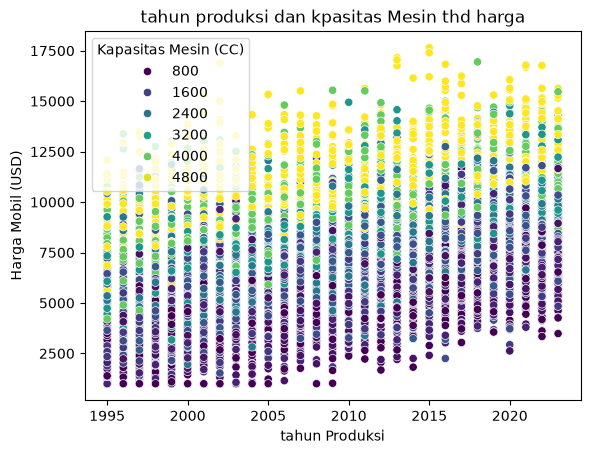

In [15]:
sns.scatterplot(
    data=df,
    x='make_year',
    y='price_usd',
    hue='engine_cc',
    palette='viridis'
)

plt.title('tahun produksi dan kpasitas Mesin thd harga')
plt.xlabel('tahun Produksi')
plt.ylabel('Harga Mobil (USD)')
plt.legend(title='Kapasitas Mesin (CC)')
plt.show()

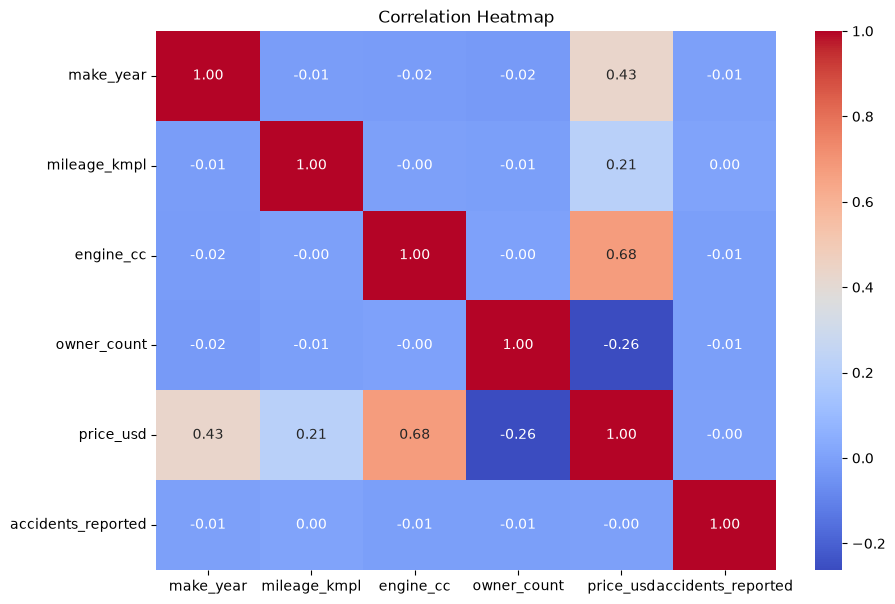

In [16]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [17]:
df['service_history'] = df['service_history'].fillna('Unknown')

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price_usd'])
y = df['price_usd']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(8000, 11)
(2000, 11)


## Feature Engineering

In [19]:
X_train['car_age'] = 2026 - X_train['make_year']
X_test['car_age'] = 2026 - X_test['make_year']

In [20]:
categorical_cols = X_train.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
print(categorical_cols)

['fuel_type', 'brand', 'transmission', 'color', 'service_history', 'insurance_valid']


In [21]:
# encoder
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

# fit nya di X_train aja, lalu transformnya ke X_train dan X_test
encoded_train = pd.DataFrame(
    encoder.fit_transform(X_train[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_train.index
)

encoded_test = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

In [22]:
# gabung fitur numerik lama fgn fitur hasil encoding
X_train = X_train.drop(columns=categorical_cols).join(encoded_train)
X_test = X_test.drop(columns=categorical_cols).join(encoded_test)

In [23]:

print(" X_train setelah pemrosesan:", X_train.shape)
print(" X_test setelah pemrosesan :", X_test.shape)
X_train.head()

 X_train setelah pemrosesan: (8000, 32)
 X_test setelah pemrosesan : (2000, 32)


,make_year,mileage_kmpl,engine_cc,owner_count,accidents_reported,car_age,fuel_type_Diesel,fuel_type_Electric,fuel_type_Petrol,brand_BMW,...,color_Blue,color_Gray,color_Red,color_Silver,color_White,service_history_Full,service_history_Partial,service_history_Unknown,insurance_valid_No,insurance_valid_Yes
9254,2002,9.70,1800,2,0,24,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1561,2004,16.10,1500,3,0,22,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1670,2005,10.51,5000,2,0,21,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6087,2019,14.27,2000,5,1,7,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
6669,2015,21.72,1000,1,0,11,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [24]:
X_train.head(5)

,make_year,mileage_kmpl,engine_cc,owner_count,accidents_reported,car_age,fuel_type_Diesel,fuel_type_Electric,fuel_type_Petrol,brand_BMW,...,color_Blue,color_Gray,color_Red,color_Silver,color_White,service_history_Full,service_history_Partial,service_history_Unknown,insurance_valid_No,insurance_valid_Yes
9254,2002,9.70,1800,2,0,24,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1561,2004,16.10,1500,3,0,22,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1670,2005,10.51,5000,2,0,21,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6087,2019,14.27,2000,5,1,7,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
6669,2015,21.72,1000,1,0,11,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [25]:
print("Jumlah kolom sebelum encoding:", df.shape[1])
print("Jumlah kolom setelah encoding:", X_train.shape[1])

Jumlah kolom sebelum encoding: 12
Jumlah kolom setelah encoding: 32


In [26]:
#supaya tidak redundan dan mengurangi multikolinearitas,hapus kolom 'make_year' krna  sudah buat kolom baru 'car_age' yg mererpresentasikan informasi yang sama.
X_train = X_train.drop(columns=['make_year'])
X_test = X_test.drop(columns=['make_year'])



In [27]:
scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)


X_train_scaled = pd.DataFrame(
    X_train_scaled, columns=X_train.columns, index=X_train.index
)
X_test_scaled = pd.DataFrame(
    X_test_scaled, columns=X_test.columns, index=X_test.index
)

## Modeling

In [28]:
#beberaapa model yg dibandingkan
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42)
}

In [29]:
results = []

for name, model in models.items():
    # fit model
    model.fit(X_train, y_train)
    
    # Prediksi
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    
    # Hitung metrik
    r2_tr = r2_score(y_train, y_pred_train)
    r2_te = r2_score(y_test, y_pred_test)
    mae = mean_absolute_error(y_test, y_pred_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
    
    results.append({
        'Model': name,
        'R2 Train': round(r2_tr, 4),
        'R2 Test': round(r2_te, 4),
        'MAE ($)': round(mae, 2),
        'RMSE ($)': round(rmse, 2)
    })

In [30]:
df_results = pd.DataFrame(results).sort_values(by='R2 Test', ascending=False).reset_index(drop=True)
display(df_results)

,Model,R2 Train,R2 Test,MAE ($),RMSE ($)
0,Linear Regression,0.8709,0.8765,791.00,991.02
1,Gradient Boosting,0.8780,0.8712,805.09,1012.44
2,Random Forest,0.9788,0.8520,864.42,1085.07
3,Decision Tree,1.0000,0.7032,1226.11,1536.75


C:\Users\User\AppData\Local\Temp\ipykernel_34620\4195587927.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x='R2 Test', y='Model', ax=axes[0], palette='Blues_r')
C:\Users\User\AppData\Local\Temp\ipykernel_34620\4195587927.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_results, x='MAE ($)', y='Model', ax=axes[1], palette='Reds_r')


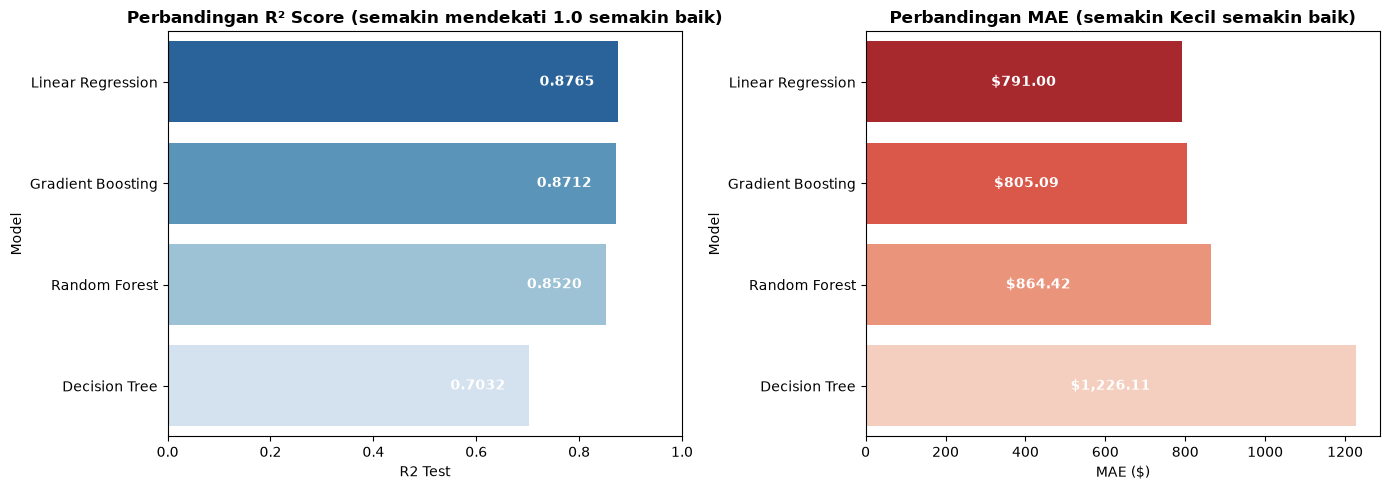

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#R2 Score (Test Set)
sns.barplot(data=df_results, x='R2 Test', y='Model', ax=axes[0], palette='Blues_r')
axes[0].set_title('Perbandingan R² Score (semakin mendekati 1.0 semakin baik)', fontweight='bold')
axes[0].set_xlim(0, 1.0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_width():.4f}", (p.get_width() - 0.1, p.get_y() + p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

# MAE (Test Set)
sns.barplot(data=df_results, x='MAE ($)', y='Model', ax=axes[1], palette='Reds_r')
axes[1].set_title('Perbandingan MAE (semakin Kecil semakin baik)', fontweight='bold')
for p in axes[1].patches:
    axes[1].annotate(f"${p.get_width():,.2f}", (p.get_width() / 2, p.get_y() + p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

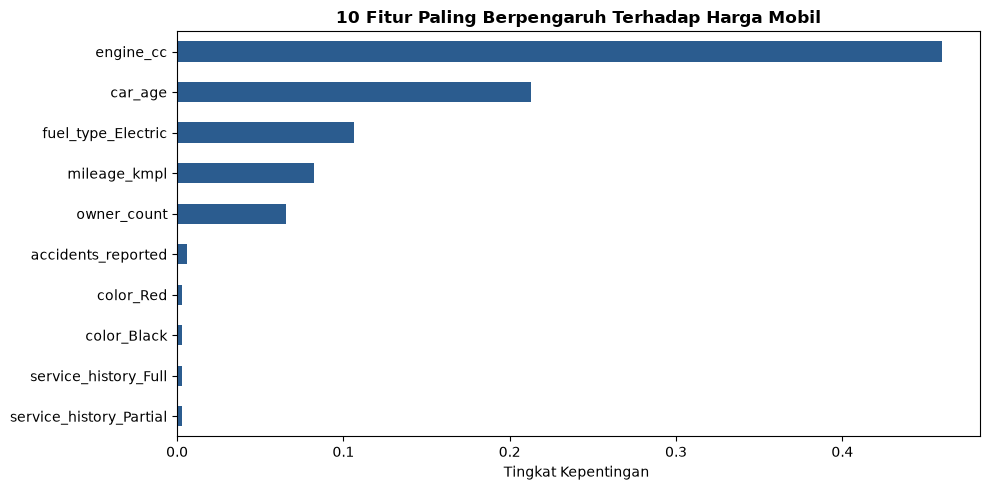

In [32]:
model_rf = models['Random Forest']
# 10 fitur yang paling mempengaruhi harga
importances = pd.Series(model_rf.feature_importances_, index=X_train.columns)

plt.figure(figsize=(10, 5))
importances.nlargest(10).plot(kind='barh', color='#2b5c8f')
plt.title('10 Fitur Paling Berpengaruh Terhadap Harga Mobil', fontsize=12, fontweight='bold')
plt.xlabel('Tingkat Kepentingan ')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

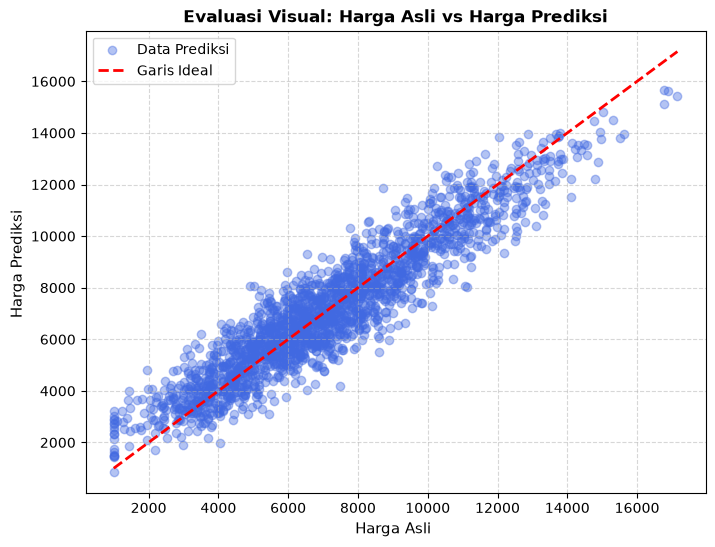

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_test, alpha=0.4, color='royalblue', label='Data Prediksi')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Garis Ideal')

plt.xlabel('Harga Asli ', fontsize=11)
plt.ylabel('Harga Prediksi ', fontsize=11)
plt.title('Evaluasi Visual: Harga Asli vs Harga Prediksi', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [34]:

sample_data = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = models['Linear Regression'].predict(sample_data)[0]

print(f"Harga Asli Mobil     : ${actual_price:,.2f}")
print(f"Harga Hasil Prediksi : ${predicted_price:,.2f}")
print(f"Selisih (Error)      : ${abs(actual_price - predicted_price):,.2f}")

Harga Asli Mobil     : $12,772.12
Harga Hasil Prediksi : $12,124.39
Selisih (Error)      : $647.73
